<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HancockGPTCN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# HANCOCK GPT-2 CLASSIFIER
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))
# ============================================================
# 6. CONVERT EXACTLY SIX CLINICAL FEATURES INTO TEXT
# ============================================================

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def patient_to_text(row):

    # Feature 1: Age
    age = display_value(row["age_at_initial_diagnosis"])

    # Feature 2: Sex
    sex_value = str(row["sex"]).strip().lower()

    if sex_value in ["1", "male", "m"]:
        sex = "male"
    elif sex_value in ["0", "female", "f"]:
        sex = "female"
    else:
        sex = display_value(row["sex"])

    # Feature 3: Smoking status
    smoking_value = str(row["smoking_status"]).strip().lower()

    if smoking_value in ["0", "non-smoker", "nonsmoker", "never"]:
        smoking = "a non-smoker"
    elif smoking_value in ["1", "smoker", "current smoker", "yes"]:
        smoking = "a smoker"
    else:
        smoking = display_value(row["smoking_status"])

    # Feature 4: Primary tumour site
    site = display_value(row["primary_tumor_site"])

    # Feature 5: Primarily metastasis
    metastasis = display_value(row["primarily_metastasis"])

    # Feature 6: Pathological N stage
    n_stage = display_value(row["pN_stage"])

    prompt = (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available. "

        f"This patient is {age} years old and is {sex}. "
        f"The patient is {smoking}. "
        f"The primary tumour site is {site}. "
        f"The primarily metastasis status is {metastasis}. "
        f"Pathological nodal stage is {n_stage}. "

        "Based on these six clinical features, "
        "predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\nA:"
    )

    return prompt


# Verify exactly six input features
features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

assert len(features) == 6

print("Number of clinical features:", len(features))
print("Features:", features)

print("\nExample clinical prompt:")
print(patient_to_text(df.iloc[0]))

# ============================================================
# 7. LOAD TOKENIZER AND SELECT MAXIMUM LENGTH
# ============================================================
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Determine the length policy from training prompts only to avoid
# using validation/test data to choose preprocessing parameters.
train_texts = [patient_to_text(row) for _, row in train_df.iterrows()]

train_texts = [patient_to_text(row) for _, row in train_df.iterrows()]

TRAIN_PROMPT_LENGTHS = [
    len(tokenizer.encode(t, add_special_tokens=False))
    for t in train_texts
]

print(
    "Training prompt tokens: min =", min(TRAIN_PROMPT_LENGTHS),
    "| median =", int(np.median(TRAIN_PROMPT_LENGTHS)),
    "| 95th percentile =", int(np.percentile(TRAIN_PROMPT_LENGTHS, 95)),
    "| max =", max(TRAIN_PROMPT_LENGTHS)
)

MAX_LENGTH = min(1024, max(32, int(np.ceil(max(TRAIN_PROMPT_LENGTHS) / 8) * 8)))

if max(TRAIN_PROMPT_LENGTHS) > 1024:
    print("WARNING: Some training prompts exceed GPT-2's context limit.")

print("Selected MAX_LENGTH:", MAX_LENGTH)

if max(TRAIN_PROMPT_LENGTHS) > 1024:
    print("WARNING: Some training prompts exceed GPT-2's context limit.")

print("Selected MAX_LENGTH:", MAX_LENGTH)

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS,
      "| Learning rate:", LEARNING_RATE,
      "| Weight decay:", WEIGHT_DECAY)

# ============================================================
# 8. BUILD DATASETS AND DATA LOADERS
# ============================================================
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            encoded = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                encoded["input_ids"].squeeze(0),
                encoded["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        input_ids, attention_mask, label = self.items[index]
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "label": torch.tensor(label, dtype=torch.long)
        }

val_texts = [patient_to_text(row) for _, row in val_df.iterrows()]
test_texts = [patient_to_text(row) for _, row in test_df.iterrows()]

train_dataset = HPVTextDataset(train_texts, y_train)
val_dataset = HPVTextDataset(val_texts, y_val)
test_dataset = HPVTextDataset(test_texts, y_test)
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)


# ============================================================
# 9. INITIALISE FROZEN GPT-2 CLASSIFIER AND CLASS WEIGHTS
# ============================================================

class HPVNetGPT2Text(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_classes=2,
                 dropout=DROPOUT):
        super().__init__()

        # Load GPT-2 backbone
        self.gpt2 = GPT2Model.from_pretrained(model_name)

        # FREEZE ALL GPT-2 PARAMETERS
        for param in self.gpt2.parameters():
            param.requires_grad = False

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        hidden_size = self.gpt2.config.hidden_size

        # CLASSIFIER HEAD REMAINS TRAINABLE
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        hidden_states = outputs.last_hidden_state

        # Pool the final non-padding token
        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]

        return self.classifier(pooled_output)


# Initialise model
model = HPVNetGPT2Text().to(device)

# Verify trainable parameters
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters() if p.requires_grad
)

classifier_trainable = sum(
    p.numel() for p in model.classifier.parameters() if p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Classifier trainable parameters:", classifier_trainable)
print("Total trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Class weights
class_counts = np.bincount(y_train, minlength=2)

class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print("Class weights [negative, positive]:",
      class_weights.detach().cpu().numpy())

# Loss function
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Optimise ONLY the classifier head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 10. HPV SCORES, VALIDATION LOSS AND THRESHOLD SELECTION
# ============================================================
def get_hpv_scores(loader):
    model.eval()
    scores, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels_all.extend(batch["label"].numpy())
    return np.asarray(scores, dtype=float), np.asarray(labels_all, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total_loss, total_examples = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            loss = weighted_classification_loss(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n
    return total_loss / max(total_examples, 1)

def select_threshold(scores, labels):
    thresholds = np.unique(np.concatenate(([0.0], scores, [1.0])))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    # Maximise balanced accuracy; ties go to the threshold closest to 0.5.
    return max(results, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# ============================================================
# 11. TRAIN AND SAVE BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR = Path("ROC_HANCOCK_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":
        OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": {
        "value": float("inf"), "epoch": None, "threshold": None
    },
    "Validation_ROC_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_PR_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_Balanced_Accuracy": {
        "value": -float("inf"), "epoch": None, "threshold": None
    }
}
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    train_loss_sum, train_examples = 0.0, 0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = weighted_classification_loss(logits, labels)
        loss.backward()
        optimizer.step()
        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_examples += n

    train_loss = train_loss_sum / max(train_examples, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_hpv_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    val_threshold, val_ba = select_threshold(val_scores, val_labels)
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss,
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba
    }
    for metric, value in metrics.items():
        improved = (
            value < best[metric]["value"] if metric == "Validation_Loss"
            else value > best[metric]["value"]
        )
        if improved:
            best[metric] = {
                "value": float(value), "epoch": epoch,
                "threshold": float(val_threshold)
            }
            torch.save(model.state_dict(), checkpoint_paths[metric])

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric, "Best_Epoch": info["epoch"],
        "Best_Validation_Metric": info["value"],
        "Threshold_Selected_On_Validation": info["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, info in best.items()
])
best_summary.to_csv(
    OUT_DIR / "best_validation_checkpoints.csv", index=False
)
print("\nBEST VALIDATION CHECKPOINTS\n", best_summary.to_string(index=False))

# ============================================================
# 12. EVALUATE CHECKPOINTS ON THE HELD-OUT TEST SET
# ============================================================
test_results, test_predictions = [], {}
for metric, path in checkpoint_paths.items():
    print(f"\n===== CHECKPOINT: {metric} =====")
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_hpv_scores(test_loader)
    threshold = best[metric]["threshold"]
    predictions = (scores >= threshold).astype(int)
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, zero_division=0)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    print("Best epoch:", best[metric]["epoch"])
    print(f"Validation threshold: {threshold:.6f}")
    print(classification_report(
        labels, predictions, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(
        f"Test ROC-AUC: {auc:.4f} | Test PR-AUC (AP): {ap:.4f} | "
        f"Test Balanced Accuracy: {ba:.4f} | F1: {f1:.4f}"
    )
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    test_results.append({
        "Dataset": "HANCOCK", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": auc, "Test_PR_AUC_Average_Precision": ap,
        "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })
    test_predictions[metric] = {
        "scores": scores, "predictions": predictions,
        "labels": labels, "threshold": threshold
    }
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": predictions, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{metric.lower()}.csv", index=False)

results_df = pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)
print("\nTEST RESULTS BY CHECKPOINT\n", results_df.to_string(index=False))

# ============================================================
# 13. SAVE ROC AND PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================
for metric, result in test_predictions.items():
    labels, scores = result["labels"], result["scores"]
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    safe_name = metric.lower()
    pd.DataFrame({
        "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
    }).to_csv(OUT_DIR / f"roc_coordinates_{safe_name}.csv", index=False)
    pd.DataFrame({
        "Precision": precision, "Recall": recall
    }).to_csv(
        OUT_DIR / f"precision_recall_coordinates_{safe_name}.csv",
        index=False
    )
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"HANCOCK GPT-2 Classifier ROC: {metric}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"roc_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(recall, precision, linewidth=2, label=f"PR-AUC (AP) = {ap:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"HANCOCK GPT-2 Classifier Precision-Recall: {metric}")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"precision_recall_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

# ============================================================
# 14. SAVE SETTINGS AND APPEND RESULTS TO COMPARISON CSV
# ============================================================
settings = {
    "Dataset": "HANCOCK", "Model": MODEL_NAME,
    "Model_Type": "GPT-2 Classifier",
    "Features": ", ".join(features), "Number_of_Features": len(features),
    "Target": target_col, "Positive_Class": 1,
    "Positive_Class_Name": "HPV Positive",
    "Learning_Rate": LEARNING_RATE, "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW", "Epochs": EPOCHS, "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Max_Length_Method": (
        "Training prompts only; rounded to multiple of 8; capped at 1024"
    ),
    "Random_Seed": SEED, "Train_Validation_Test_Split": "65/15/20 stratified",
    "SMOTE": False, "Gradient_Clipping": False,
    "GPT2_Backbone_Frozen": True, "Dropout": DROPOUT,
    "Class_Weights": str(class_weights.detach().cpu().numpy().tolist()),
    "Checkpoint_Selection": (
        "Best validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "Threshold_Selection": (
        "Maximise validation balanced accuracy; ties closest to 0.5"
    ),
    "HPV_Positive_Score": "Softmax probability for class 1 (HPV positive)",
    "Curves": (
        "Test ROC and precision-recall curves saved for each checkpoint"
    )
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison_rows = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC_Average_Precision",
    "Test_Balanced_Accuracy", "Test_F1"
]].rename(columns={"Test_PR_AUC_Average_Precision": "Test_PR_AUC"})

if comparison_file.exists():
    existing = pd.read_csv(comparison_file)
    for col in comparison_rows.columns:
        if col not in existing.columns:
            existing[col] = np.nan
    for col in existing.columns:
        if col not in comparison_rows.columns:
            comparison_rows[col] = np.nan
    combined = pd.concat(
        [existing, comparison_rows[existing.columns]], ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison_rows

combined.to_csv(comparison_file, index=False)
print("\nSaved classifier outputs to:", OUT_DIR.resolve())
print("AUC comparison file:", comparison_file.resolve())

Device: cuda
Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Number of clinical features: 6
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

Example clinical prompt:
Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. This patient is 60 years old and is male. The patient is a non-smoker. The primary tumour site is Oropharynx. The primarily metastasis status is no. Pathological nodal stage is pN1. Based on these six clinical features, predict whether the patient is HPV positive or HPV negative. Answer with only Yes or No.
A:
Tra

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Total trainable parameters: 100226
Class weights [negative, positive]: [0.87398374 1.1684783 ]
Epoch 50/500 | Train Loss=0.6965 | Val Loss=0.6911 | Val ROC-AUC=0.6626 | Val PR-AUC=0.5907 | Val BA=0.6831 | Threshold=0.517035
Epoch 100/500 | Train Loss=0.6919 | Val Loss=0.6875 | Val ROC-AUC=0.6593 | Val PR-AUC=0.6003 | Val BA=0.6831 | Threshold=0.497462
Epoch 150/500 | Train Loss=0.6954 | Val Loss=0.6863 | Val ROC-AUC=0.6626 | Val PR-AUC=0.6029 | Val BA=0.7003 | Threshold=0.423658
Epoch 200/500 | Train Loss=0.6686 | Val Loss=0.6715 | Val ROC-AUC=0.6724 | Val PR-AUC=0.6076 | Val BA=0.7176 | Threshold=0.456804
Epoch 250/500 | Train Loss=0.6598 | Val Loss=0.6680 | Val ROC-AUC=0.6708 | Val PR-AUC=0.6104 | Val BA=0.7003 | Threshold=0.462380
Epoch 300/500 | Train Loss=0.6767 | Val Loss=0.6649 | Val ROC-AUC=0.6741 | Val PR-AUC=0.6117 | Val BA=0.7003 | Threshold=0.383093
Epoch 350/500 | Train Loss=0.6474 | Val Loss=0.6599 | Va

Checkpoint contents: odict_keys(['gpt2.wte.weight', 'gpt2.wpe.weight', 'gpt2.h.0.ln_1.weight', 'gpt2.h.0.ln_1.bias', 'gpt2.h.0.attn.c_attn.weight', 'gpt2.h.0.attn.c_attn.bias', 'gpt2.h.0.attn.c_proj.weight', 'gpt2.h.0.attn.c_proj.bias', 'gpt2.h.0.ln_2.weight', 'gpt2.h.0.ln_2.bias', 'gpt2.h.0.mlp.c_fc.weight', 'gpt2.h.0.mlp.c_fc.bias', 'gpt2.h.0.mlp.c_proj.weight', 'gpt2.h.0.mlp.c_proj.bias', 'gpt2.h.1.ln_1.weight', 'gpt2.h.1.ln_1.bias', 'gpt2.h.1.attn.c_attn.weight', 'gpt2.h.1.attn.c_attn.bias', 'gpt2.h.1.attn.c_proj.weight', 'gpt2.h.1.attn.c_proj.bias', 'gpt2.h.1.ln_2.weight', 'gpt2.h.1.ln_2.bias', 'gpt2.h.1.mlp.c_fc.weight', 'gpt2.h.1.mlp.c_fc.bias', 'gpt2.h.1.mlp.c_proj.weight', 'gpt2.h.1.mlp.c_proj.bias', 'gpt2.h.2.ln_1.weight', 'gpt2.h.2.ln_1.bias', 'gpt2.h.2.attn.c_attn.weight', 'gpt2.h.2.attn.c_attn.bias', 'gpt2.h.2.attn.c_proj.weight', 'gpt2.h.2.attn.c_proj.bias', 'gpt2.h.2.ln_2.weight', 'gpt2.h.2.ln_2.bias', 'gpt2.h.2.mlp.c_fc.weight', 'gpt2.h.2.mlp.c_fc.bias', 'gpt2.h.2.mlp.c

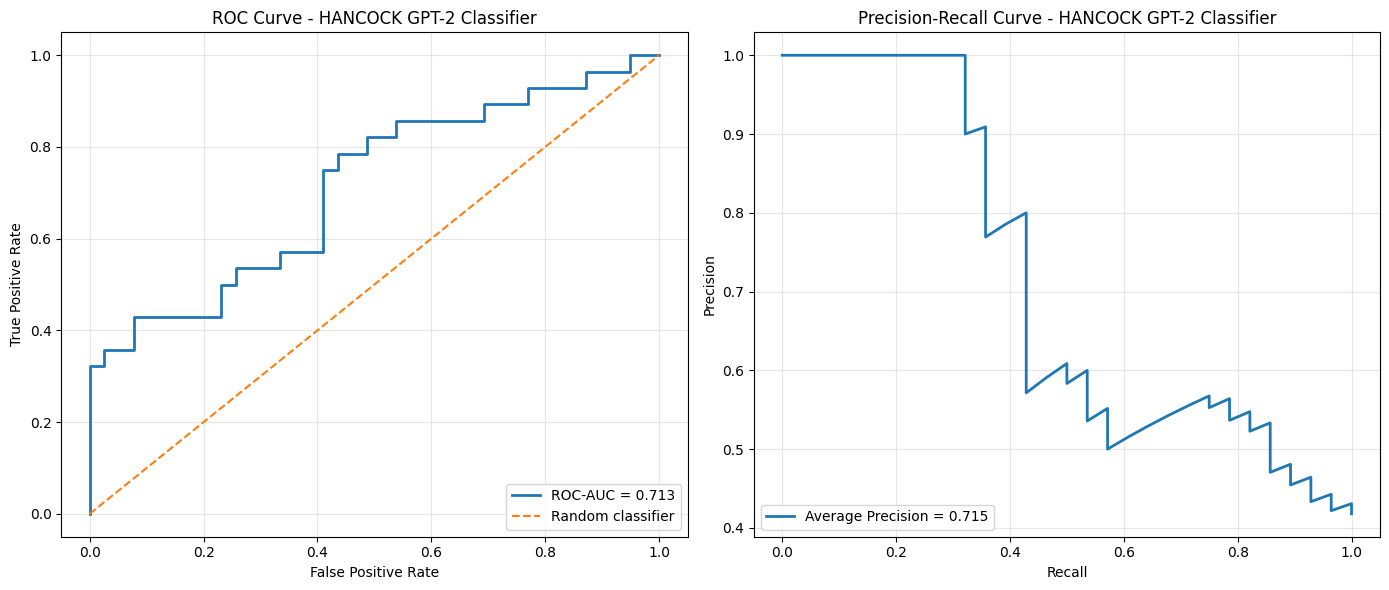

Epoch 497 Test ROC-AUC: 0.7134
Epoch 497 Test PR-AUC (AP): 0.7150


In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# 1. Load the epoch 497 checkpoint
checkpoint_path = (
    "/content/ROC_HANCOCK_GPT2_CLASSIFIER/"
    "best_model_validation_loss.pth"
)

checkpoint = torch.load(checkpoint_path, map_location=device)
print("Checkpoint contents:", checkpoint.keys() if isinstance(checkpoint, dict) else type(checkpoint))

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model" in checkpoint:
    state_dict = checkpoint["model"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)
model.to(device)
model.eval()

# 2. Load test labels and get predicted probabilities
y_true = np.asarray(y_test).astype(int)
y_scores = []

model.eval()

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        logits = model(input_ids, attention_mask)
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        y_scores.extend(probabilities.cpu().numpy())

y_scores = np.asarray(y_scores)

# Confirm that predictions and labels match
assert len(y_true) == len(y_scores), (
    f"Mismatch: {len(y_true)} labels and {len(y_scores)} predictions"
)

# 3. Calculate ROC curve and AUC
fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 4. Calculate Precision-Recall curve and AP
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_scores
)
pr_auc = average_precision_score(y_true, y_scores)

# 5. Plot ROC and PR curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC curve
axes[0].plot(
    fpr, tpr,
    label=f"ROC-AUC = {roc_auc:.3f}",
    linewidth=2
)
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve - HANCOCK GPT-2 Classifier")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Precision-Recall curve
axes[1].plot(
    recall, precision,
    label=f"Average Precision = {pr_auc:.3f}",
    linewidth=2
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve - HANCOCK GPT-2 Classifier")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Epoch 497 Test ROC-AUC: {roc_auc:.4f}")
print(f"Epoch 497 Test PR-AUC (AP): {pr_auc:.4f}")

Device: cuda
Number of folds: 3
Epochs: 500

FULL DATASET USED
Total patients: 332
Class counts [negative, positive]:
[191 141]

Features:
['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

STARTING FOLD 1/3

Training examples: 187
Validation examples: 34
Held-out test examples: 111
Training classes: [107  80]
Validation classes: [20 14]
Test classes: [64 47]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Fold 1 | Epoch 50/500 | Train Loss=0.6935 | Val Loss=0.6866 | ROC-AUC=0.7321 | PR-AUC=0.6739 | BA=0.7536
Fold 1 | Epoch 100/500 | Train Loss=0.6952 | Val Loss=0.6838 | ROC-AUC=0.7357 | PR-AUC=0.6732 | BA=0.7429
Fold 1 | Epoch 150/500 | Train Loss=0.6889 | Val Loss=0.6697 | ROC-AUC=0.7429 | PR-AUC=0.6804 | BA=0.7536
Fold 1 | Epoch 200/500 | Train Loss=0.6759 | Val Loss=0.6608 | ROC-AUC=0.7429 | PR-AUC=0.6791 | BA=0.7536
Fold 1 | Epoch 250/500 | Train Loss=0.6633 | Val Loss=0.6448 | ROC-AUC=0.7464 | PR-AUC=0.6433 | BA=0.7536
Fold 1 | Epoch 300/500 | Train Loss=0.6536 | Val Loss=0.6476 | ROC-AUC=0.7179 | PR-AUC=0.5570 | BA=0.7536
Fold 1 | Epoch 350/500 | Train Loss=0.6532 | Val Loss=0.6319 | ROC-AUC=0.7250 | PR-AUC=0.5701 | BA=0.7536
Fold 1 | Epoch 400/500 | Train Loss=0.6815 | Val Loss=0.6328 | ROC-AUC=0.7250 | PR-AUC=0.5686 | BA=0.7536
Fold 1 | Epoch 450/500 | Train Loss=0.6443 | Val Loss=0.6277 | ROC-AUC=0.7250 | PR

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Fold 2 | Epoch 50/500 | Train Loss=0.6965 | Val Loss=0.6871 | ROC-AUC=0.7250 | PR-AUC=0.6219 | BA=0.7929
Fold 2 | Epoch 100/500 | Train Loss=0.6902 | Val Loss=0.6834 | ROC-AUC=0.7571 | PR-AUC=0.6981 | BA=0.7679
Fold 2 | Epoch 150/500 | Train Loss=0.6791 | Val Loss=0.6723 | ROC-AUC=0.7464 | PR-AUC=0.6468 | BA=0.7929
Fold 2 | Epoch 200/500 | Train Loss=0.6669 | Val Loss=0.6569 | ROC-AUC=0.7500 | PR-AUC=0.6469 | BA=0.7679
Fold 2 | Epoch 250/500 | Train Loss=0.6603 | Val Loss=0.6408 | ROC-AUC=0.7321 | PR-AUC=0.6321 | BA=0.7679
Fold 2 | Epoch 300/500 | Train Loss=0.6510 | Val Loss=0.6322 | ROC-AUC=0.7143 | PR-AUC=0.5937 | BA=0.7321
Fold 2 | Epoch 350/500 | Train Loss=0.6881 | Val Loss=0.6643 | ROC-AUC=0.6893 | PR-AUC=0.5721 | BA=0.7179
Fold 2 | Epoch 400/500 | Train Loss=0.6444 | Val Loss=0.6266 | ROC-AUC=0.6821 | PR-AUC=0.5622 | BA=0.6929
Fold 2 | Epoch 450/500 | Train Loss=0.6499 | Val Loss=0.6589 | ROC-AUC=0.6786 | PR

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Fold 3 | Epoch 50/500 | Train Loss=0.6967 | Val Loss=0.6880 | ROC-AUC=0.5821 | PR-AUC=0.5374 | BA=0.6714
Fold 3 | Epoch 100/500 | Train Loss=0.6877 | Val Loss=0.6856 | ROC-AUC=0.5857 | PR-AUC=0.5043 | BA=0.6714
Fold 3 | Epoch 150/500 | Train Loss=0.6932 | Val Loss=0.6854 | ROC-AUC=0.5964 | PR-AUC=0.5084 | BA=0.6714
Fold 3 | Epoch 200/500 | Train Loss=0.6898 | Val Loss=0.6888 | ROC-AUC=0.6000 | PR-AUC=0.5098 | BA=0.6714
Fold 3 | Epoch 250/500 | Train Loss=0.6807 | Val Loss=0.6680 | ROC-AUC=0.6071 | PR-AUC=0.5163 | BA=0.6714
Fold 3 | Epoch 300/500 | Train Loss=0.6627 | Val Loss=0.6651 | ROC-AUC=0.6250 | PR-AUC=0.5396 | BA=0.6964
Fold 3 | Epoch 350/500 | Train Loss=0.6581 | Val Loss=0.6647 | ROC-AUC=0.6143 | PR-AUC=0.5357 | BA=0.6964
Fold 3 | Epoch 400/500 | Train Loss=0.6546 | Val Loss=0.6590 | ROC-AUC=0.6143 | PR-AUC=0.5702 | BA=0.6964
Fold 3 | Epoch 450/500 | Train Loss=0.6526 | Val Loss=0.6700 | ROC-AUC=0.6143 | PR

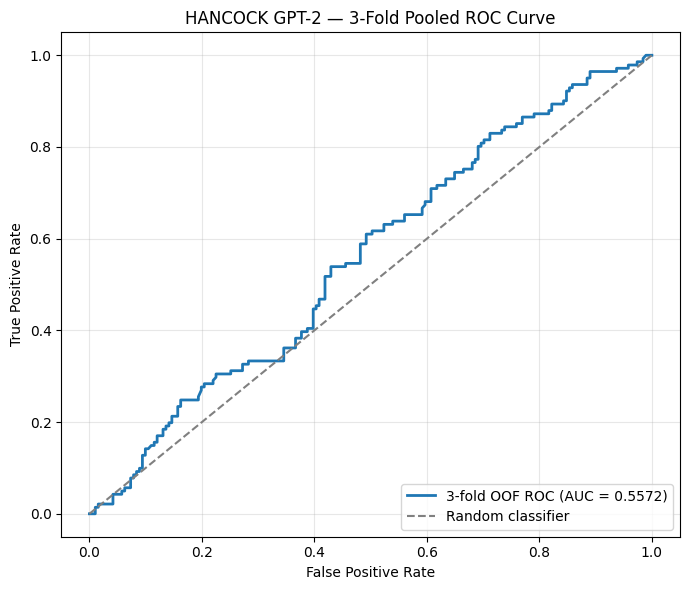

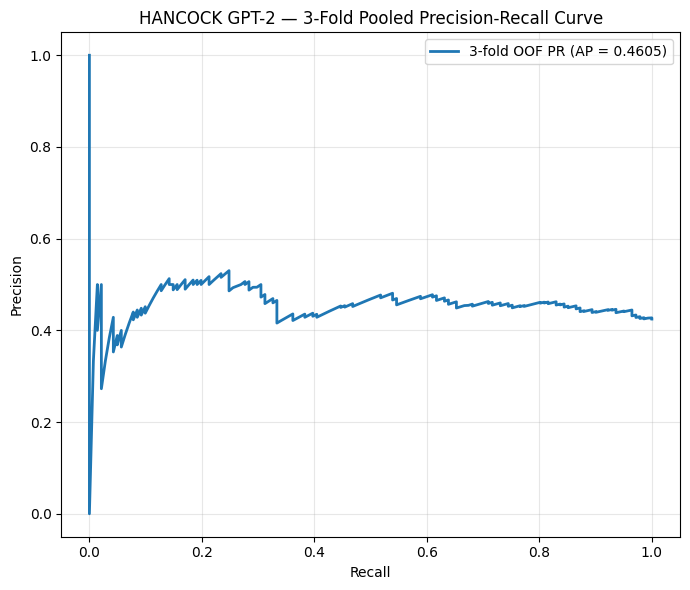


THREE-FOLD EXPERIMENT COMPLETED
All outputs saved to:
/content/ROC_HANCOCK_GPT2_3Fold


In [10]:

# ============================================================
# HANCOCK GPT-2 CLASSIFIER
# STRATIFIED 3-FOLD CROSS-VALIDATION
# Entire dataset | Frozen GPT-2 | Six clinical features
# ============================================================

import os
import gc
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42
N_FOLDS = 3

EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

VALIDATION_SIZE = 0.15

# Match the previous 3-fold experiment.
# Your prompts are approximately 100 tokens long.
MAX_LENGTH = 128

OUT_DIR = Path("/content/ROC_HANCOCK_GPT2_3Fold")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

print("Device:", device)
print("Number of folds:", N_FOLDS)
print("Epochs:", EPOCHS)


# ============================================================
# 2. USE THE ENTIRE HANCOCK DATASET
# ============================================================

df = df.reset_index(drop=True).copy()

df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

FEATURES = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis",
    "pN_stage"
]

TARGET = "HPV_Label"

missing = [
    col for col in FEATURES + [TARGET]
    if col not in df.columns
]

if missing:
    raise KeyError(f"Missing columns: {missing}")

X = df[FEATURES].copy()
y = df[TARGET].to_numpy(dtype=int)

if set(np.unique(y)) != {0, 1}:
    raise ValueError("Both HPV classes must be present.")

print("\nFULL DATASET USED")
print("Total patients:", len(df))
print("Class counts [negative, positive]:")
print(np.bincount(y, minlength=2))

print("\nFeatures:")
print(FEATURES)

assert len(FEATURES) == 6


# ============================================================
# 3. IMPUTATION — TRAINING DATA ONLY
# ============================================================

def impute_fold_data(train_df, val_df, test_df):

    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()

    fill_values = {}

    for col in FEATURES:

        if pd.api.types.is_numeric_dtype(train_df[col]):

            value = train_df[col].median()

            if pd.isna(value):
                value = 0

        else:

            modes = (
                train_df[col]
                .dropna()
                .astype(str)
                .mode()
            )

            value = modes.iloc[0] if not modes.empty else "Unknown"

        fill_values[col] = value

        for split in (train_df, val_df, test_df):

            split[col] = split[col].fillna(value)

            if split[col].dtype == object:

                split[col] = (
                    split[col]
                    .astype(str)
                    .replace({
                        "": "Unknown",
                        "nan": "Unknown",
                        "None": "Unknown"
                    })
                )

    return train_df, val_df, test_df, fill_values


# ============================================================
# 4. SCORING AND EVALUATION FUNCTIONS
# ============================================================

def make_weighted_loss(y_train):

    counts = np.bincount(y_train, minlength=2)

    weights = torch.tensor(
        len(y_train) / (2 * np.maximum(counts, 1)),
        dtype=torch.float32,
        device=device
    )

    def loss_function(logits, labels):

        losses = F.cross_entropy(
            logits,
            labels,
            reduction="none"
        )

        return (losses * weights[labels]).mean()

    return loss_function


def get_scores(model, loader):

    model.eval()

    scores = []
    labels_all = []

    with torch.no_grad():

        for batch in loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)

            logits = model(ids, mask)

            probabilities = torch.softmax(
                logits, dim=1
            )[:, 1]

            scores.extend(probabilities.cpu().numpy())
            labels_all.extend(batch["label"].numpy())

    return (
        np.asarray(scores, dtype=float),
        np.asarray(labels_all, dtype=int)
    )


def evaluate_loss(model, loader, loss_function):

    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():

        for batch in loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(ids, mask)
            loss = loss_function(logits, labels)

            n = len(labels)

            total_loss += loss.item() * n
            total_examples += n

    return total_loss / max(total_examples, 1)


def choose_threshold(scores, labels):

    thresholds = np.unique(
        np.r_[0.0, scores, 1.0]
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                labels,
                scores >= t
            )
        )
        for t in thresholds
    ]

    return max(
        results,
        key=lambda item: (
            item[1],
            -abs(item[0] - 0.5)
        )
    )


# ============================================================
# 5. STRATIFIED THREE-FOLD CROSS-VALIDATION
# ============================================================

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Store one held-out prediction for every patient.
oof_scores = np.full(len(df), np.nan)
oof_predictions = np.full(len(df), -1, dtype=int)
oof_fold = np.full(len(df), -1, dtype=int)

fold_results = []
fold_histories = []

loader_args = {
    "batch_size": BATCH_SIZE,
    "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}


for fold, (train_val_idx, test_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    print("\n" + "=" * 65)
    print(f"STARTING FOLD {fold}/{N_FOLDS}")
    print("=" * 65)

    seed_everything(SEED + fold)

    # --------------------------------------------------------
    # OUTER TRAINING AND HELD-OUT TEST FOLD
    # --------------------------------------------------------

    fold_train_val = df.iloc[train_val_idx].copy()
    fold_test = df.iloc[test_idx].copy()

    # --------------------------------------------------------
    # INNER TRAINING AND VALIDATION SPLIT
    # --------------------------------------------------------

    inner_train, inner_val = train_test_split(
        fold_train_val,
        test_size=VALIDATION_SIZE,
        random_state=SEED + fold,
        stratify=fold_train_val[TARGET]
    )

    # --------------------------------------------------------
    # IMPUTE USING INNER TRAINING DATA ONLY
    # --------------------------------------------------------

    inner_train, inner_val, fold_test, fill_values = (
        impute_fold_data(
            inner_train,
            inner_val,
            fold_test
        )
    )

    y_train = inner_train[TARGET].to_numpy(dtype=int)
    y_val = inner_val[TARGET].to_numpy(dtype=int)
    y_test = fold_test[TARGET].to_numpy(dtype=int)

    print("\nTraining examples:", len(y_train))
    print("Validation examples:", len(y_val))
    print("Held-out test examples:", len(y_test))

    print("Training classes:", np.bincount(y_train, minlength=2))
    print("Validation classes:", np.bincount(y_val, minlength=2))
    print("Test classes:", np.bincount(y_test, minlength=2))

    if len(np.unique(y_val)) < 2 or len(np.unique(y_test)) < 2:
        raise ValueError(
            f"Fold {fold}: validation or test set lacks one class."
        )

    # --------------------------------------------------------
    # BUILD CLINICAL NARRATIVES
    # --------------------------------------------------------

    train_texts = [
        patient_to_text(row)
        for _, row in inner_train.iterrows()
    ]

    val_texts = [
        patient_to_text(row)
        for _, row in inner_val.iterrows()
    ]

    test_texts = [
        patient_to_text(row)
        for _, row in fold_test.iterrows()
    ]

    # --------------------------------------------------------
    # BUILD DATASETS
    # --------------------------------------------------------

    train_ds = HPVTextDataset(train_texts, y_train)
    val_ds = HPVTextDataset(val_texts, y_val)
    test_ds = HPVTextDataset(test_texts, y_test)

    generator = torch.Generator().manual_seed(SEED + fold)

    train_loader = DataLoader(
        train_ds,
        shuffle=True,
        generator=generator,
        **loader_args
    )

    val_loader = DataLoader(
        val_ds,
        shuffle=False,
        **loader_args
    )

    test_loader = DataLoader(
        test_ds,
        shuffle=False,
        **loader_args
    )

    # --------------------------------------------------------
    # INITIALISE A FRESH FROZEN GPT-2 MODEL
    # --------------------------------------------------------

    model = HPVNetGPT2Text().to(device)

    # Confirm that GPT-2 remains frozen.
    gpt2_trainable = sum(
        p.numel()
        for p in model.gpt2.parameters()
        if p.requires_grad
    )

    classifier_trainable = sum(
        p.numel()
        for p in model.classifier.parameters()
        if p.requires_grad
    )

    print("\nGPT-2 trainable parameters:", gpt2_trainable)
    print("Classifier trainable parameters:", classifier_trainable)

    assert gpt2_trainable == 0

    # Class weights calculated from this fold's training data.
    loss_function = make_weighted_loss(y_train)

    # Optimise ONLY the classifier.
    optimizer = torch.optim.AdamW(
        model.classifier.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # --------------------------------------------------------
    # CHECKPOINT SELECTION
    # Best validation PR-AUC.
    # --------------------------------------------------------

    best_val_ap = -float("inf")
    best_epoch = None
    best_threshold = None
    best_state = None

    history = []

    # --------------------------------------------------------
    # TRAIN FOR 500 EPOCHS
    # No early stopping.
    # --------------------------------------------------------

    for epoch in range(1, EPOCHS + 1):

        model.train()

        # Keep frozen GPT-2 in evaluation mode.
        model.gpt2.eval()

        loss_sum = 0.0
        n_sum = 0

        for batch in train_loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(ids, mask)
            loss = loss_function(logits, labels)

            loss.backward()
            optimizer.step()

            n = len(labels)

            loss_sum += loss.item() * n
            n_sum += n

        train_loss = loss_sum / max(n_sum, 1)

        # Validation evaluation.
        val_loss = evaluate_loss(
            model,
            val_loader,
            loss_function
        )

        val_scores, val_labels = get_scores(
            model,
            val_loader
        )

        val_auc = roc_auc_score(
            val_labels,
            val_scores
        )

        val_ap = average_precision_score(
            val_labels,
            val_scores
        )

        threshold, val_ba = choose_threshold(
            val_scores,
            val_labels
        )

        history.append({
            "Fold": fold,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Validation_Loss": val_loss,
            "Validation_ROC_AUC": val_auc,
            "Validation_PR_AUC": val_ap,
            "Validation_Balanced_Accuracy": val_ba,
            "Validation_Threshold": threshold
        })

        # Select the best checkpoint using validation PR-AUC.
        if val_ap > best_val_ap:

            best_val_ap = float(val_ap)
            best_epoch = epoch
            best_threshold = float(threshold)

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        if epoch % 50 == 0:

            print(
                f"Fold {fold} | Epoch {epoch}/{EPOCHS} | "
                f"Train Loss={train_loss:.4f} | "
                f"Val Loss={val_loss:.4f} | "
                f"ROC-AUC={val_auc:.4f} | "
                f"PR-AUC={val_ap:.4f} | "
                f"BA={val_ba:.4f}"
            )

    fold_histories.extend(history)

    # --------------------------------------------------------
    # EVALUATE BEST CHECKPOINT ON HELD-OUT TEST FOLD
    # --------------------------------------------------------

    model.load_state_dict(best_state)
    model.to(device)

    test_scores, test_labels = get_scores(
        model,
        test_loader
    )

    assert np.array_equal(test_labels, y_test)

    test_predictions = (
        test_scores >= best_threshold
    ).astype(int)

    test_auc = roc_auc_score(
        test_labels,
        test_scores
    )

    test_ap = average_precision_score(
        test_labels,
        test_scores
    )

    test_ba = balanced_accuracy_score(
        test_labels,
        test_predictions
    )

    test_f1 = f1_score(
        test_labels,
        test_predictions,
        zero_division=0
    )

    cm = confusion_matrix(
        test_labels,
        test_predictions,
        labels=[0, 1]
    )

    print("\nFOLD", fold, "BEST CHECKPOINT")
    print("Best epoch:", best_epoch)
    print("Best validation PR-AUC:", round(best_val_ap, 4))
    print("Validation threshold:", round(best_threshold, 6))

    print("\nHeld-out test classification report:")

    print(
        classification_report(
            test_labels,
            test_predictions,
            labels=[0, 1],
            target_names=["HPV Negative", "HPV Positive"],
            digits=4,
            zero_division=0
        )
    )

    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)

    print(
        f"\nFOLD {fold} TEST RESULTS | "
        f"ROC-AUC={test_auc:.4f} | "
        f"PR-AUC={test_ap:.4f} | "
        f"BA={test_ba:.4f} | "
        f"F1={test_f1:.4f}"
    )

    fold_results.append({
        "Fold": fold,
        "Best_Epoch": best_epoch,
        "Validation_PR_AUC": best_val_ap,
        "Threshold": best_threshold,
        "ROC_AUC": test_auc,
        "PR_AUC": test_ap,
        "Balanced_Accuracy": test_ba,
        "F1": test_f1,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
        "Test_N": len(test_idx)
    })

    # Save out-of-fold predictions in original dataset order.
    oof_scores[test_idx] = test_scores
    oof_predictions[test_idx] = test_predictions
    oof_fold[test_idx] = fold

    # Save fold checkpoint.
    torch.save(
        best_state,
        OUT_DIR / f"best_model_fold_{fold}.pth"
    )

    # Save fold-specific training history.
    pd.DataFrame(history).to_csv(
        OUT_DIR / f"training_history_fold_{fold}.csv",
        index=False
    )

    # Release GPU memory.
    del model
    del optimizer
    del train_loader, val_loader, test_loader
    del train_ds, val_ds, test_ds
    del best_state

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 6. VERIFY FULL DATASET COVERAGE
# ============================================================

assert not np.isnan(oof_scores).any(), (
    "Some patients are missing out-of-fold scores."
)

assert (oof_predictions >= 0).all(), (
    "Some patients are missing predictions."
)

assert (oof_fold >= 1).all(), (
    "Some patients were not assigned to a test fold."
)

assert len(oof_scores) == len(df)

print("\n" + "=" * 65)
print("CROSS-VALIDATION COVERAGE CHECK")
print("=" * 65)

print("Total patients:", len(df))
print("Patients tested:", len(oof_scores))

print("\nPatients assigned to each held-out fold:")
print(pd.Series(oof_fold).value_counts().sort_index())

print("\nEvery patient was held out exactly once.")


# ============================================================
# 7. MEAN AND STANDARD DEVIATION ACROSS THREE FOLDS
# ============================================================

fold_results_df = pd.DataFrame(fold_results)

metric_columns = [
    "ROC_AUC",
    "PR_AUC",
    "Balanced_Accuracy",
    "F1"
]

summary_rows = []

for metric in metric_columns:

    mean_value = fold_results_df[metric].mean()
    sd_value = fold_results_df[metric].std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "SD": sd_value,
        "Mean ± SD": (
            f"{mean_value:.4f} ± {sd_value:.4f}"
        )
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 65)
print("HANCOCK GPT-2 — THREE-FOLD RESULTS: MEAN ± SD")
print("=" * 65)

print(summary_df.to_string(index=False))

print("\nIndividual fold results:")
print(
    fold_results_df[
        ["Fold", "Best_Epoch"] + metric_columns
    ].to_string(index=False)
)


# ============================================================
# 8. POOLED OUT-OF-FOLD METRICS
# ============================================================

pooled_auc = roc_auc_score(y, oof_scores)
pooled_ap = average_precision_score(y, oof_scores)

pooled_ba = balanced_accuracy_score(
    y,
    oof_predictions
)

pooled_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

pooled_cm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\n" + "=" * 65)
print("POOLED OUT-OF-FOLD RESULTS")
print("=" * 65)

print(f"Pooled ROC-AUC: {pooled_auc:.4f}")
print(f"Pooled PR-AUC: {pooled_ap:.4f}")
print(f"Pooled Balanced Accuracy: {pooled_ba:.4f}")
print(f"Pooled F1: {pooled_f1:.4f}")

print("\nPooled confusion matrix [[TN, FP], [FN, TP]]:")
print(pooled_cm)


# ============================================================
# 9. POOLED OUT-OF-FOLD ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y, oof_scores)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"3-fold OOF ROC (AUC = {pooled_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HANCOCK GPT-2 — 3-Fold Pooled ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "3fold_pooled_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. POOLED OUT-OF-FOLD PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(
    y,
    oof_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"3-fold OOF PR (AP = {pooled_ap:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HANCOCK GPT-2 — 3-Fold Pooled Precision-Recall Curve")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "3fold_pooled_PR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. SAVE ALL EXPERIMENT RESULTS
# ============================================================

fold_results_df.to_csv(
    OUT_DIR / "3fold_individual_results.csv",
    index=False
)

summary_df.to_csv(
    OUT_DIR / "3fold_mean_sd_results.csv",
    index=False
)

pd.DataFrame(fold_histories).to_csv(
    OUT_DIR / "3fold_training_history.csv",
    index=False
)

oof_df = pd.DataFrame({
    "Patient_Index": df.index,
    "True_Label": y,
    "OOF_Predicted_Probability": oof_scores,
    "OOF_Predicted_Label": oof_predictions,
    "Held_Out_Fold": oof_fold
})

oof_df.to_csv(
    OUT_DIR / "3fold_out_of_fold_predictions.csv",
    index=False
)

pooled_results = pd.DataFrame([{
    "Dataset": "HANCOCK",
    "Model": "Frozen GPT-2 Classifier",
    "Pooled_ROC_AUC": pooled_auc,
    "Pooled_PR_AUC": pooled_ap,
    "Pooled_Balanced_Accuracy": pooled_ba,
    "Pooled_F1": pooled_f1,
    "Total_Patients": len(df),
    "Number_of_Folds": N_FOLDS
}])

pooled_results.to_csv(
    OUT_DIR / "3fold_pooled_metrics.csv",
    index=False
)

settings = pd.DataFrame([{
    "Dataset": "HANCOCK",
    "Model": "GPT-2 Classifier",
    "Features": ", ".join(FEATURES),
    "Number_of_Features": len(FEATURES),
    "Total_Patients": len(df),
    "Folds": N_FOLDS,
    "Validation_Size": VALIDATION_SIZE,
    "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH,
    "Seed": SEED,
    "GPT2_Backbone_Frozen": True,
    "Checkpoint_Selection": "Validation PR-AUC",
    "Threshold_Selection": "Validation Balanced Accuracy",
    "SMOTE": False
}])

settings.to_csv(
    OUT_DIR / "3fold_settings.csv",
    index=False
)

print("\n" + "=" * 65)
print("THREE-FOLD EXPERIMENT COMPLETED")
print("=" * 65)

print("All outputs saved to:")
print(OUT_DIR.resolve())


In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load individual fold results
results_path = Path(
    "/content/ROC_HANCOCK_GPT2_3Fold/3fold_individual_results.csv"
)

fold_results_df = pd.read_csv(results_path)

# Metrics to summarise
metrics = [
    "ROC_AUC",
    "PR_AUC",
    "Balanced_Accuracy",
    "F1"
]

# Calculate mean and sample standard deviation across 3 folds
summary = []

for metric in metrics:

    values = fold_results_df[metric].dropna()

    summary.append({
        "Metric": metric,
        "Fold 1": values.iloc[0],
        "Fold 2": values.iloc[1],
        "Fold 3": values.iloc[2],
        "Mean": values.mean(),
        "SD": values.std(ddof=1),
        "Mean ± SD": f"{values.mean():.4f} ± {values.std(ddof=1):.4f}"
    })

mean_sd_df = pd.DataFrame(summary)

print("\nHANCOCK GPT-2 CLASSIFIER")
print("STRATIFIED 3-FOLD CROSS-VALIDATION")
print("=" * 75)

print(mean_sd_df.to_string(index=False))

# Save the results
mean_sd_df.to_csv(
    "/content/ROC_HANCOCK_GPT2_3Fold/3fold_mean_sd_results.csv",
    index=False
)

print("\nMean ± SD results saved successfully.")


HANCOCK GPT-2 CLASSIFIER
STRATIFIED 3-FOLD CROSS-VALIDATION
           Metric   Fold 1   Fold 2   Fold 3     Mean       SD       Mean ± SD
          ROC_AUC 0.609043 0.626828 0.657042 0.630971 0.024266 0.6310 ± 0.0243
           PR_AUC 0.474940 0.492669 0.537374 0.501661 0.032173 0.5017 ± 0.0322
Balanced_Accuracy 0.584774 0.628823 0.665653 0.626417 0.040493 0.6264 ± 0.0405
               F1 0.560748 0.585859 0.617021 0.587876 0.028191 0.5879 ± 0.0282

Mean ± SD results saved successfully.
